In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import numpy as np
import nibabel as nib
import os
import glob
from skimage.transform import resize
from tensorflow.keras.utils import to_categorical
from tensorflow.keras import layers, Model
import tensorflow as tf
from scipy.fftpack import fftn, ifftn, fftshift
from sklearn.model_selection import train_test_split
import re
from skimage.transform import resize
from tqdm import tqdm_notebook
from scipy import ndimage                                 #Center AND Cropping of Images
!pip install nibabel
import nibabel as nib
from scipy import ndimage

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.pylab as pylab

def standardize(image):

  standardized_image = np.zeros(image.shape)

  #

      # iterate over the `z` dimension
  for z in range(image.shape[2]):
      # get a slice of the image
      # at channel c and z-th dimension `z`
      image_slice = image[:,:,z]

      # subtract the mean from image_slice
      centered = image_slice - np.mean(image_slice)

      # divide by the standard deviation (only if it is different from zero)
      if(np.std(centered)!=0):
          centered = centered/np.std(centered)

      standardized_image[:, :, z] = centered

  ### END CODE HERE ###

  return standardized_image

In [ ]:
data_folder="/content/drive/MyDrive/MyData/"
patient_list = glob.glob(data_folder + 'training/' + '*')
listGround = []
listPST = []
crop_size=(50, 50, 50)
new_shape=(128,128,16)
for patient_name in patient_list:
    folder_path = os.path.join(data_folder , 'training/' , patient_name)
    for file in glob.glob(os.path.join(folder_path, 'patient???_frame??.nii.gz')):

        # Load Patient
        print (patient_name)
        patient_folder_path = os.path.join(file)
        # Read and load volume
        img = nib.load(patient_folder_path)
        img = np.array(img.get_fdata())
        # Apply enhancement
        # Normalize the intensity values
        x_img = resize(img,  new_shape, mode = 'constant', preserve_range = True).astype(np.float32)
        x_img = np.transpose(x_img, (2, 1, 0))  # Change to (16, 128, 128)
        reshaped_image=x_img[:,:,:]
        reshaped_image=x_img.reshape(16,128,128,1)

        listPST.append(reshaped_image)
    for file in glob.glob(os.path.join(folder_path, 'patient???_frame??_gt.nii.gz')):

        # Load ground truth
        GT_folder_path = os.path.join(file)
        lab = nib.load(GT_folder_path)
        lab = np.array(lab.get_fdata())
        lab = resize(lab, (128,128,16), mode = 'constant', preserve_range = True).astype(np.float32)
        label=np.transpose(lab,(2,1,0)).astype(np.float32)
        reshaped_label=label[:,:,:]
        reshaped_label=reshaped_label.reshape(16,128,128,1)
        reshaped_label[reshaped_label==4] = 3
        reshaped_label = to_categorical(reshaped_label, num_classes = 4)

        listGround.append(reshaped_label)


/content/drive/MyDrive/MyData/training/patient001
/content/drive/MyDrive/MyData/training/patient001
/content/drive/MyDrive/MyData/training/patient002
/content/drive/MyDrive/MyData/training/patient002
/content/drive/MyDrive/MyData/training/patient003
/content/drive/MyDrive/MyData/training/patient003
/content/drive/MyDrive/MyData/training/patient004
/content/drive/MyDrive/MyData/training/patient004
/content/drive/MyDrive/MyData/training/patient005
/content/drive/MyDrive/MyData/training/patient005
/content/drive/MyDrive/MyData/training/patient006
/content/drive/MyDrive/MyData/training/patient006
/content/drive/MyDrive/MyData/training/patient007
/content/drive/MyDrive/MyData/training/patient007
/content/drive/MyDrive/MyData/training/patient008
/content/drive/MyDrive/MyData/training/patient008
/content/drive/MyDrive/MyData/training/patient009
/content/drive/MyDrive/MyData/training/patient009
/content/drive/MyDrive/MyData/training/patient010
/content/drive/MyDrive/MyData/training/patient010


In [ ]:
!pip install sklearn_relief
from sklearn.model_selection import train_test_split
# Feature Selection
#rfe svm
#relief knn
train_x1, test_x1, train_y1, test_y1 = train_test_split( listPST, listGround ,test_size=0.2,random_state=0)
print("Using %s images for training and %s images for testing" % (len(train_x1), len(test_x1)))


Using 158 images for training and 40 images for testing


In [ ]:
train_x1 = np.array(train_x1)
train_y1 = np.array(train_y1)
test_x1  = np.array(test_x1)
test_y1  = np.array(test_y1)

In [ ]:
train_x1.shape,train_y1.shape,test_x1.shape,test_y1.shape

((158, 16, 128, 128, 1),
 (158, 16, 128, 128, 4),
 (40, 16, 128, 128, 1),
 (40, 16, 128, 128, 4))

In [ ]:
from tensorflow.keras import backend as K
import tensorflow as tf
"""
def calculate_psnr(original, enhanced):
    # Ensure the images have the same data type
    original = original.astype(np.float32)
    enhanced = enhanced.astype(np.float32)

    # Calculate the mean squared error
    mse = np.mean((original - enhanced) ** 2)

    if mse == 0.0:
        # Handle the case where MSE is zero
        return float('inf')

    # Calculate the maximum possible pixel value
    max_pixel_value = np.max(original)

    # Calculate PSNR
    psnr = 20 * np.log10(max_pixel_value / np.sqrt(mse))

    return psnr

def dice_coef(y_true, y_pred):
    smooth = 1e-6  # To avoid division by zero
    intersection = tf.reduce_sum(y_true * y_pred, axis=[1, 2, 3])
    union = tf.reduce_sum(y_true, axis=[1, 2, 3]) + tf.reduce_sum(y_pred, axis=[1, 2, 3])
    return tf.reduce_mean((2. * intersection + smooth) / (union + smooth))

def dice_coef(y_true, y_pred, epsilon=1e-6):
    intersection = np.sum(y_true * y_pred)
    union = np.sum(y_true) + np.sum(y_pred)
    dice = (2.0 * intersection + epsilon) / (union + epsilon)
    return dice"""
def calculate_psnr(original, enhanced):

    # Assurez-vous que les images ont le même type de données (float32 ici)
    original = tf.cast(original, tf.float32)  # Convertir en float32
    enhanced = tf.cast(enhanced, tf.float32)  # Convertir en float32

    # Calculer l'erreur quadratique moyenne (MSE)
    mse = tf.reduce_mean(tf.square(original - enhanced))

    # Avoid division by zero
    epsilon = 1e-10
    max_pixel_value = 1.0  # Assuming images are normalized between 0 and 1
    psnr = 10.0 * tf.math.log((max_pixel_value ** 2) / (mse + epsilon)) / tf.math.log(10.0)

    return psnr

def calculate_ssim(y_true, y_pred):
    # Ensure the images are in float32 type
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)

    # Compute SSIM
    ssim = tf.image.ssim(y_true, y_pred, max_val=1.0)  # Set max_val appropriately (e.g., 1.0 for normalized images, 255.0 for 8-bit images)

    return tf.reduce_mean(ssim)  # Return the mean SSIM over the batch
def dice_coefficient(y_true, y_pred, epsilon=1e-6):
    # Flatten the tensors
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])

    # Compute Dice coefficient
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    dice_numerator = 2. * intersection + epsilon
    dice_denominator = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + epsilon
    return tf.reduce_mean(dice_numerator / dice_denominator)

def dice_coef_loss(y_true, y_pred):
    return 1-dice_coefficient(y_true, y_pred)

def IoU_coef(y_true, y_pred):
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    return (intersection + 1.0) / (K.sum(y_true_f) + K.sum(y_pred_f) - intersection + 1.0)
# Fonction pour calculer la PSNR


def specificity(y_true, y_pred, epsilon=1e-6):
    """
    Compute specificity between true labels and predicted labels.
    """
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])

    tn = tf.reduce_sum((1 - y_true_f) * (1 - y_pred_f))
    fp = tf.reduce_sum((1 - y_true_f) * y_pred_f)

    return tn / (tn + fp + epsilon)  # Avoid division by zero
import tensorflow as tf

import tensorflow as tf

def sensitivity(y_true, y_pred, epsilon=1e-6):
    """
    Compute sensitivity (recall) between true labels and predicted labels.
    """
    y_pred = tf.cast(y_pred > 0.5, tf.float32)  # Convertir en binaire
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])

    tp = tf.reduce_sum(y_true_f * y_pred_f)
    fn = tf.reduce_sum(y_true_f * (1 - y_pred_f))

    return tp / (tp + fn + epsilon)  # Éviter la division par zéro

def precision(y_true, y_pred, epsilon=1e-6):
    """
    Compute precision between true labels and predicted labels.
    """
    y_pred = tf.cast(y_pred > 0.5, tf.float32)  # Convertir en binaire
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])

    tp = tf.reduce_sum(y_true_f * y_pred_f)
    fp = tf.reduce_sum((1 - y_true_f) * y_pred_f)

    return tp / (tp + fp + epsilon)  # Éviter la division par zéro


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.utils import to_categorical
import numpy as np
import glob
import os
import nibabel as nib
from skimage.transform import resize
from tensorflow.keras.callbacks import ModelCheckpoint

import tensorflow as tf
from tensorflow.keras import layers
from keras.layers import Input, BatchNormalization, Activation, Dense, Dropout
from keras.layers import Input, BatchNormalization, Activation, Dense, Dropout,Maximum
from keras.layers import Conv3D,Conv3DTranspose
from keras.layers import MaxPooling3D, GlobalMaxPool3D
from keras.layers import Input, UpSampling3D
from tensorflow.keras.layers import concatenate
from tensorflow.keras.callbacks import EarlyStopping



In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, Model


# ============================================================
# CONFIGURATION
# ============================================================

INPUT_SHAPE = (16, 128, 128, 1)
NUM_CLASSES = 4

BASE_FILTERS = 8
MAMBA_STATE = 8
MAMBA_EXPAND = 1

DROPOUT = 0.10


# ============================================================
# BASIC 3D CONVOLUTION BLOCK
# ============================================================

class ConvBlock3D(layers.Layer):

    def __init__(self, filters, dropout=0.0, **kwargs):
        super().__init__(**kwargs)

        self.filters = filters

        self.conv1 = layers.Conv3D(
            filters,
            3,
            padding="same",
            use_bias=False
        )

        self.bn1 = layers.BatchNormalization()
        self.act1 = layers.Activation("swish")

        self.conv2 = layers.Conv3D(
            filters,
            3,
            padding="same",
            use_bias=False
        )

        self.bn2 = layers.BatchNormalization()

        self.dropout = (
            layers.Dropout(dropout)
            if dropout > 0
            else None
        )

        self.act2 = layers.Activation("swish")

        self.projection = None

    def build(self, input_shape):

        if input_shape[-1] != self.filters:

            self.projection = layers.Conv3D(
                self.filters,
                1,
                padding="same",
                use_bias=False
            )

        super().build(input_shape)

    def call(self, x, training=None):

        residual = x

        y = self.conv1(x)
        y = self.bn1(
            y,
            training=training
        )
        y = self.act1(y)

        y = self.conv2(y)
        y = self.bn2(
            y,
            training=training
        )

        if self.dropout is not None:

            y = self.dropout(
                y,
                training=training
            )

        if self.projection is not None:

            residual = self.projection(
                residual
            )

        y = y + residual
        y = self.act2(y)

        return y


# ============================================================
# 3D BOUNDARY EXTRACTION
# ============================================================

class BoundaryBranch3D(layers.Layer):

    def __init__(self, filters, **kwargs):
        super().__init__(**kwargs)

        self.proj = layers.Conv3D(
            filters,
            1,
            padding="same",
            use_bias=False
        )

        self.bn = layers.BatchNormalization()

    def call(self, x, training=None):

        # ----------------------------------------------------
        # DEPTH GRADIENT
        # ----------------------------------------------------

        dz = (
            x[:, 1:, :, :, :]
            -
            x[:, :-1, :, :, :]
        )

        dz = tf.pad(
            dz,
            [
                [0, 0],
                [0, 1],
                [0, 0],
                [0, 0],
                [0, 0]
            ]
        )

        # ----------------------------------------------------
        # HEIGHT GRADIENT
        # ----------------------------------------------------

        dy = (
            x[:, :, 1:, :, :]
            -
            x[:, :, :-1, :, :]
        )

        dy = tf.pad(
            dy,
            [
                [0, 0],
                [0, 0],
                [0, 1],
                [0, 0],
                [0, 0]
            ]
        )

        # ----------------------------------------------------
        # WIDTH GRADIENT
        # ----------------------------------------------------

        dx = (
            x[:, :, :, 1:, :]
            -
            x[:, :, :, :-1, :]
        )

        dx = tf.pad(
            dx,
            [
                [0, 0],
                [0, 0],
                [0, 0],
                [0, 1],
                [0, 0]
            ]
        )

        # ----------------------------------------------------
        # 3D GRADIENT MAGNITUDE
        # ----------------------------------------------------

        boundary = tf.sqrt(
            dx * dx
            +
            dy * dy
            +
            dz * dz
            +
            1e-6
        )

        boundary = self.proj(boundary)

        boundary = self.bn(
            boundary,
            training=training
        )

        return tf.nn.swish(boundary)


# ============================================================
# MULTI-SCALE CONTEXT
# ============================================================

class MultiScaleContext3D(layers.Layer):

    def __init__(self, filters, **kwargs):
        super().__init__(**kwargs)

        # Local context
        self.local = layers.Conv3D(
            filters,
            3,
            padding="same",
            use_bias=False
        )

        # Medium-range context
        self.medium = layers.Conv3D(
            filters,
            3,
            dilation_rate=2,
            padding="same",
            use_bias=False
        )

        # Large-range context
        self.large = layers.Conv3D(
            filters,
            5,
            padding="same",
            use_bias=False
        )

        self.fusion = layers.Conv3D(
            filters,
            1,
            padding="same",
            use_bias=False
        )

        self.bn = layers.BatchNormalization()

    def call(self, x, training=None):

        f_local = self.local(x)

        f_medium = self.medium(x)

        f_large = self.large(x)

        y = tf.concat(
            [
                f_local,
                f_medium,
                f_large
            ],
            axis=-1
        )

        y = self.fusion(y)

        y = self.bn(
            y,
            training=training
        )

        return tf.nn.swish(y)


# ============================================================
# SELECTIVE SCAN 1D
# ============================================================

class SelectiveScan1D(layers.Layer):

    def __init__(
        self,
        channels,
        state_size=8,
        **kwargs
    ):
        super().__init__(**kwargs)

        self.channels = channels
        self.state_size = state_size

        # Input-dependent time step
        self.dt_proj = layers.Dense(
            state_size,
            activation="softplus"
        )

        # State-space B
        self.B_proj = layers.Dense(
            state_size
        )

        # State-space C
        self.C_proj = layers.Dense(
            state_size
        )

        # Input projection to state dimension
        self.x_proj = layers.Dense(
            state_size
        )

        # State output projection
        self.out_proj = layers.Dense(
            channels
        )

        # Learnable A parameter
        self.A_log = self.add_weight(
            name="A_log",
            shape=(state_size,),
            initializer=tf.keras.initializers.Constant(
                -2.0
            ),
            trainable=True
        )

        # Skip parameter
        self.D = self.add_weight(
            name="D",
            shape=(channels,),
            initializer="ones",
            trainable=True
        )

    def call(self, x):

        # x = [B, L, C]

        batch_size = tf.shape(x)[0]

        # ----------------------------------------------------
        # INPUT-DEPENDENT PARAMETERS
        # ----------------------------------------------------

        dt = self.dt_proj(x)

        B_t = self.B_proj(x)

        C_t = self.C_proj(x)

        x_state = self.x_proj(x)

        # ----------------------------------------------------
        # STABLE STATE MATRIX
        # ----------------------------------------------------

        A = -tf.exp(
            self.A_log
        )

        # ----------------------------------------------------
        # SEQUENCE-FIRST FORMAT
        # ----------------------------------------------------

        x_seq = tf.transpose(
            x_state,
            [1, 0, 2]
        )

        dt_seq = tf.transpose(
            dt,
            [1, 0, 2]
        )

        B_seq = tf.transpose(
            B_t,
            [1, 0, 2]
        )

        C_seq = tf.transpose(
            C_t,
            [1, 0, 2]
        )

        # ----------------------------------------------------
        # INITIAL STATE
        # ----------------------------------------------------

        h0 = tf.zeros(
            [
                batch_size,
                self.state_size
            ],
            dtype=x.dtype
        )

        y0 = tf.zeros(
            [
                batch_size,
                self.channels
            ],
            dtype=x.dtype
        )

        # ----------------------------------------------------
        # SCAN FUNCTION
        # ----------------------------------------------------

        def scan_fn(
            state,
            inputs
        ):

            h_prev, _ = state

            x_t = inputs[0]
            dt_t = inputs[1]
            B_t_current = inputs[2]
            C_t_current = inputs[3]

            # Discretized decay
            decay = tf.exp(
                dt_t * A
            )

            # State update
            h_new = (
                decay * h_prev
                +
                B_t_current * x_t
            )

            # Output state
            y_state = (
                C_t_current * h_new
            )

            y = self.out_proj(
                y_state
            )

            return (
                h_new,
                y
            )

        # ----------------------------------------------------
        # SCAN INPUT
        # ----------------------------------------------------

        scan_inputs = tf.stack(
            [
                x_seq,
                dt_seq,
                B_seq,
                C_seq
            ],
            axis=1
        )

        # ----------------------------------------------------
        # SELECTIVE SCAN
        # ----------------------------------------------------

        _, outputs = tf.scan(
            scan_fn,
            scan_inputs,
            initializer=(
                h0,
                y0
            )
        )

        # [L, B, C] -> [B, L, C]

        outputs = tf.transpose(
            outputs,
            [1, 0, 2]
        )

        return outputs


# ============================================================
# BIDIRECTIONAL SELECTIVE SCAN
# ============================================================

class BidirectionalSelectiveScan3D(layers.Layer):

    def __init__(
        self,
        channels,
        state_size=8,
        **kwargs
    ):
        super().__init__(**kwargs)

        self.forward_scan = SelectiveScan1D(
            channels,
            state_size
        )

        self.backward_scan = SelectiveScan1D(
            channels,
            state_size
        )

        self.fusion = layers.Dense(
            channels
        )

    def call(self, x):

        # ----------------------------------------------------
        # FORWARD SCAN
        # ----------------------------------------------------

        forward = self.forward_scan(x)

        # ----------------------------------------------------
        # BACKWARD SCAN
        # ----------------------------------------------------

        x_reverse = tf.reverse(
            x,
            axis=[1]
        )

        backward = self.backward_scan(
            x_reverse
        )

        backward = tf.reverse(
            backward,
            axis=[1]
        )

        # ----------------------------------------------------
        # BIDIRECTIONAL FUSION
        # ----------------------------------------------------

        y = tf.concat(
            [
                forward,
                backward
            ],
            axis=-1
        )

        return self.fusion(y)


# ============================================================
# 3D AXIS MAMBA
# ============================================================

class Mamba3DAxis(layers.Layer):

    def __init__(
        self,
        channels,
        state_size=8,
        **kwargs
    ):
        super().__init__(**kwargs)

        self.channels = channels

        self.norm = layers.LayerNormalization()

        self.in_proj = layers.Dense(
            channels * 2
        )

        self.depthwise = layers.Conv3D(
            channels * 2,
            3,
            padding="same",
            groups=channels * 2
        )

        # Depth
        self.scan_D = (
            BidirectionalSelectiveScan3D(
                channels,
                state_size
            )
        )

        # Height
        self.scan_H = (
            BidirectionalSelectiveScan3D(
                channels,
                state_size
            )
        )

        # Width
        self.scan_W = (
            BidirectionalSelectiveScan3D(
                channels,
                state_size
            )
        )

        self.out_proj = layers.Dense(
            channels
        )

    def call(self, x):

        residual = x

        # ----------------------------------------------------
        # NORMALIZATION
        # ----------------------------------------------------

        x = self.norm(x)

        # ----------------------------------------------------
        # FEATURE + GATE PROJECTION
        # ----------------------------------------------------

        x = self.in_proj(x)

        x = self.depthwise(x)

        u, gate = tf.split(
            x,
            2,
            axis=-1
        )

        # Dynamic shape
        shape = tf.shape(u)

        B = shape[0]
        D = shape[1]
        H = shape[2]
        W = shape[3]
        C = shape[4]

        # ====================================================
        # DEPTH AXIS
        # ====================================================

        xd = tf.transpose(
            u,
            [0, 2, 3, 1, 4]
        )

        xd = tf.reshape(
            xd,
            [
                B * H * W,
                D,
                C
            ]
        )

        yd = self.scan_D(xd)

        yd = tf.reshape(
            yd,
            [
                B,
                H,
                W,
                D,
                C
            ]
        )

        yd = tf.transpose(
            yd,
            [0, 3, 1, 2, 4]
        )

        # ====================================================
        # HEIGHT AXIS
        # ====================================================

        xh = tf.transpose(
            u,
            [0, 1, 3, 2, 4]
        )

        xh = tf.reshape(
            xh,
            [
                B * D * W,
                H,
                C
            ]
        )

        yh = self.scan_H(xh)

        yh = tf.reshape(
            yh,
            [
                B,
                D,
                W,
                H,
                C
            ]
        )

        yh = tf.transpose(
            yh,
            [0, 1, 3, 2, 4]
        )

        # ====================================================
        # WIDTH AXIS
        # ====================================================

        xw = tf.reshape(
            u,
            [
                B * D * H,
                W,
                C
            ]
        )

        yw = self.scan_W(xw)

        yw = tf.reshape(
            yw,
            [
                B,
                D,
                H,
                W,
                C
            ]
        )

        # ====================================================
        # MULTI-AXIS MAMBA UNIFICATION
        # ====================================================

        y = (
            yd
            +
            yh
            +
            yw
        ) / 3.0

        # ----------------------------------------------------
        # MAMBA GATE
        # ----------------------------------------------------

        gate = tf.nn.sigmoid(gate)

        y = y * gate

        y = self.out_proj(y)

        # ----------------------------------------------------
        # RESIDUAL
        # ----------------------------------------------------

        return residual + y


# ============================================================
# C-VSS 3D
#
# CORE MAMBA BLOCK USED BY SUM
# ============================================================

class CVSS3D(layers.Layer):

    def __init__(
        self,
        channels,
        state_size=8,
        expand=2,
        dropout=0.1,
        **kwargs
    ):
        super().__init__(**kwargs)

        self.norm = layers.LayerNormalization()

        self.expand = layers.Dense(
            channels * expand * 2
        )

        self.mamba = Mamba3DAxis(
            channels * expand,
            state_size
        )

        self.project = layers.Dense(
            channels
        )

        self.dropout = layers.Dropout(
            dropout
        )

    def call(
        self,
        x,
        training=None
    ):

        residual = x

        x = self.norm(x)

        x = self.expand(x)

        x, gate = tf.split(
            x,
            2,
            axis=-1
        )

        x = self.mamba(x)

        x = x * tf.nn.silu(
            gate
        )

        x = self.project(x)

        x = self.dropout(
            x,
            training=training
        )

        return residual + x


# ============================================================
# SUM 3D
# Sequential Unification through Mamba
# Attention-free Mamba feature unification
# ============================================================

class SUM3D(layers.Layer):

    def __init__(
        self,
        channels,
        num_blocks=2,
        state_size=8,
        expand=2,
        dropout=0.1,
        **kwargs
    ):
        super().__init__(**kwargs)

        self.channels = channels

        # ----------------------------------------------------
        # MAMBA BLOCKS
        # ----------------------------------------------------

        self.mamba_blocks = [
            CVSS3D(
                channels,
                state_size=state_size,
                expand=expand,
                dropout=dropout
            )
            for _ in range(num_blocks)
        ]

        # ----------------------------------------------------
        # NORMALIZATION
        # ----------------------------------------------------

        self.norm = layers.LayerNormalization()

        # ----------------------------------------------------
        # FEATURE FUSION
        # ----------------------------------------------------

        self.fusion = layers.Conv3D(
            channels,
            1,
            padding="same",
            use_bias=False
        )

        self.fusion_bn = layers.BatchNormalization()

    def call(self, x, training=None):

        residual = x
        y = x

        # ----------------------------------------------------
        # MAMBA FEATURE MODELING
        # ----------------------------------------------------

        for block in self.mamba_blocks:
            y = block(y, training=training)

        # ----------------------------------------------------
        # FEATURE NORMALIZATION AND PROJECTION
        # ----------------------------------------------------

        y = self.norm(y)
        y = self.fusion(y)
        y = self.fusion_bn(y, training=training)
        y = tf.nn.swish(y)

        # ----------------------------------------------------
        # RESIDUAL FEATURE UNIFICATION
        # ----------------------------------------------------

        return y + residual


# ============================================================
# DOWN-SAMPLING
# ============================================================

class Downsample3D(layers.Layer):

    def __init__(
        self,
        filters,
        **kwargs
    ):
        super().__init__(**kwargs)

        self.conv = layers.Conv3D(
            filters,
            3,
            strides=2,
            padding="same",
            use_bias=False
        )

        self.bn = layers.BatchNormalization()

    def call(
        self,
        x,
        training=None
    ):

        x = self.conv(x)

        x = self.bn(
            x,
            training=training
        )

        return tf.nn.swish(x)


# ============================================================
# UPSAMPLING
# ============================================================

class Upsample3D(layers.Layer):

    def __init__(
        self,
        filters,
        **kwargs
    ):
        super().__init__(**kwargs)

        self.up = layers.Conv3DTranspose(
            filters,
            2,
            strides=2,
            padding="same",
            use_bias=False
        )

        self.bn = layers.BatchNormalization()

    def call(
        self,
        x,
        training=None
    ):

        x = self.up(x)

        x = self.bn(
            x,
            training=training
        )

        return tf.nn.swish(x)


# ============================================================
# DECODER BLOCK
# ============================================================

class DecoderBlock3D(layers.Layer):

    def __init__(
        self,
        filters,
        **kwargs
    ):
        super().__init__(**kwargs)

        self.conv = ConvBlock3D(
            filters,
            dropout=DROPOUT
        )

    def call(
        self,
        x,
        skip,
        training=None
    ):

        # Normally the transposed convolution already
        # produces the correct dimensions.

        x = tf.concat(
            [
                x,
                skip
            ],
            axis=-1
        )

        return self.conv(
            x,
            training=training
        )


# ============================================================
# COMPLETE ACDC MODEL
#
# ATTENTION-FREE SUM/MAMBA
# ============================================================

def build_ACDC_SUM_MAMBA(
    input_shape=INPUT_SHAPE,
    num_classes=NUM_CLASSES,
    base_filters=BASE_FILTERS
):

    inputs = layers.Input(
        shape=input_shape,
        name="MRI_3D"
    )

    # ========================================================
    # STEM
    # ========================================================

    x = layers.Conv3D(
        base_filters,
        3,
        padding="same",
        use_bias=False
    )(inputs)

    x = layers.BatchNormalization()(x)

    x = layers.Activation(
        "swish"
    )(x)

    # ========================================================
    # ENCODER 1
    # ========================================================

    e1 = ConvBlock3D(
        base_filters,
        dropout=DROPOUT
    )(x)

    # ========================================================
    # ENCODER 2
    # ========================================================

    x = Downsample3D(
        base_filters * 2
    )(e1)

    e2 = ConvBlock3D(
        base_filters * 2,
        dropout=DROPOUT
    )(x)

    e2 = SUM3D(
        base_filters * 2,
        num_blocks=1,
        state_size=MAMBA_STATE,
        expand=2,
        dropout=DROPOUT
    )(
        e2
    )

    # ========================================================
    # ENCODER 3
    # ========================================================

    x = Downsample3D(
        base_filters * 4
    )(e2)

    e3 = ConvBlock3D(
        base_filters * 4,
        dropout=DROPOUT
    )(x)

    e3 = SUM3D(
        base_filters * 4,
        num_blocks=1,
        state_size=MAMBA_STATE,
        expand=2,
        dropout=DROPOUT
    )(
        e3
    )

    # ========================================================
    # BOTTLENECK
    # ========================================================

    x = Downsample3D(
        base_filters * 8
    )(e3)

    x = ConvBlock3D(
        base_filters * 8,
        dropout=DROPOUT
    )(x)

    x = SUM3D(
        base_filters * 8,
        num_blocks=2,
        state_size=MAMBA_STATE,
        expand=2,
        dropout=DROPOUT
    )(
        x
    )

    # ========================================================
    # DECODER 3
    # ========================================================

    x = Upsample3D(
        base_filters * 4
    )(x)

    x = layers.Concatenate()(
        [
            x,
            e3
        ]
    )

    x = ConvBlock3D(
        base_filters * 4,
        dropout=DROPOUT
    )(x)

    # ========================================================
    # DECODER 2
    # ========================================================

    x = Upsample3D(
        base_filters * 2
    )(x)

    x = layers.Concatenate()(
        [
            x,
            e2
        ]
    )

    x = ConvBlock3D(
        base_filters * 2,
        dropout=DROPOUT
    )(x)

    # ========================================================
    # DECODER 1
    # ========================================================

    x = Upsample3D(
        base_filters
    )(x)

    x = layers.Concatenate()(
        [
            x,
            e1
        ]
    )

    x = ConvBlock3D(
        base_filters,
        dropout=DROPOUT
    )(x)

    # ========================================================
    # SEGMENTATION HEAD
    # ========================================================

    outputs = layers.Conv3D(
        num_classes,
        1,
        padding="same",
        activation="softmax",
        name="segmentation"
    )(x)

    # ========================================================
    # MODEL
    # ========================================================

    return Model(
        inputs,
        outputs,
        name="ACDC_SUM_Mamba3D"
    )


# ============================================================
# BUILD MODEL
# ============================================================

model = build_ACDC_SUM_MAMBA()

model.summary()

Model: "ACDC_SUM_Mamba3D"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ MRI_3D (InputLayer) │ (None, 16, 128,   │          0 │ -                 │
│                     │ 128, 1)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d (Conv3D)     │ (None, 16, 128,   │        216 │ MRI_3D[0][0]      │
│                     │ 128, 8)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 16, 128,   │         32 │ conv3d[0][0]      │
│ (BatchNormalizatio… │ 128, 8)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 16, 128,   │          0 │ batch_normalizat… │
│ (Activation)        │ 128, 8)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_block3d        │ (None, 16, 128,   │      3,520 │ activation[0][0]  │
│ (ConvBlock3D)       │ 128, 8)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ downsample3d        │ (None, 8, 64, 64, │      3,520 │ conv_block3d[0][… │
│ (Downsample3D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_block3d_1      │ (None, 8, 64, 64, │     13,952 │ downsample3d[0][… │
│ (ConvBlock3D)       │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sum3d (SUM3D)       │ (None, 8, 64, 64, │     21,568 │ conv_block3d_1[0… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ downsample3d_1      │ (None, 4, 32, 32, │     13,952 │ sum3d[0][0]       │
│ (Downsample3D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_block3d_2      │ (None, 4, 32, 32, │     55,552 │ downsample3d_1[0… │
│ (ConvBlock3D)       │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sum3d_1 (SUM3D)     │ (None, 4, 32, 32, │     64,912 │ conv_block3d_2[0… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ downsample3d_2      │ (None, 2, 16, 16, │     55,552 │ sum3d_1[0][0]     │
│ (Downsample3D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_block3d_3      │ (None, 2, 16, 16, │    221,696 │ downsample3d_2[0… │
│ (ConvBlock3D)       │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sum3d_2 (SUM3D)     │ (None, 2, 16, 16, │    430,816 │ conv_block3d_3[0… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ upsample3d          │ (None, 4, 32, 32, │     16,512 │ sum3d_2[0][0]     │
│ (Upsample3D)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 4, 32, 32, │          0 │ upsample3d[0][0], │
│ (Concatenate)       │ 64)               │            │ sum3d_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_block3d_4      │ (None, 4, 32, 32, │     85,248 │ concatenate[0][0

 Total params: 1,019,052 (3.89 MB)

 Trainable params: 1,017,772 (3.88 MB)

 Non-trainable params: 1,280 (5.00 KB)

In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint

model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4        ),
        loss='categorical_crossentropy',
        metrics=['accuracy', dice_coefficient,sensitivity,specificity, precision, IoU_coef]
)

import time
import tensorflow as tf
import numpy as np
import platform
import psutil
from keras.callbacks import ModelCheckpoint, TensorBoard
from tensorflow.keras import backend as K
from tensorflow.python.framework.convert_to_constants import convert_variables_to_constants_v2

def get_flops(model):

    concrete = tf.function(
        lambda x: model(x)
    ).get_concrete_function(
        tf.TensorSpec([1] + list(model.input_shape[1:]), tf.float32)
    )

    frozen_func = convert_variables_to_constants_v2(concrete)

    graph_def = frozen_func.graph.as_graph_def()

    with tf.Graph().as_default() as graph:
        tf.graph_util.import_graph_def(graph_def, name="")

        run_meta = tf.compat.v1.RunMetadata()

        opts = tf.compat.v1.profiler.ProfileOptionBuilder.float_operation()

        flops = tf.compat.v1.profiler.profile(
            graph=graph,
            run_meta=run_meta,
            cmd="op",
            options=opts
        )

    return flops.total_float_ops
def train(model):
    batchSz = 1
    num_epochs = 200

    checkpoint = ModelCheckpoint(
        filepath='2.weights.h5',
        verbose=1,
        save_best_only=True,
        save_weights_only=True,
        mode='auto'
    )

    tensor_board = TensorBoard(
        log_dir='logs/',
        histogram_freq=1,
        write_images=True
    )

    # Hardware info (GPU/CPU/VRAM)
    print("\n --- HARDWARE INFORMATION ---")
    gpus = tf.config.list_physical_devices('GPU')
    if gpus:
        gpu_info = tf.config.experimental.get_device_details(gpus[0])
        print(f"GPU Model: {gpu_info.get('device_name', 'Unknown')}")
    else:
        print("No GPU detected. Using CPU.")
    print(f"CPU: {platform.processor()}")
    print(f"TensorFlow version: {tf.__version__}")
    print(f"Python version: {platform.python_version()}")
    print(f"Total System RAM: {round(psutil.virtual_memory().total / (1024**3), 2)} GB")

    # Memory requirements
    trainable_params = np.sum([K.count_params(w) for w in model.trainable_weights])
    non_trainable_params = np.sum([K.count_params(w) for w in model.non_trainable_weights])
    total_params = trainable_params + non_trainable_params
    total_memory_MB = (total_params * 4) / (1024**2)  # float32 = 4 bytes
    flops = get_flops(model)
    print(f"\nModel Parameters: {total_params:,}")
    print(f"Estimated Memory Usage: {total_memory_MB:.2f} MB")

    # Training
    start_time = time.perf_counter()
    history = model.fit(
        x=train_x1,
        y=train_y1,
        batch_size=batchSz,
        epochs=num_epochs,
        verbose=1,
        callbacks=[checkpoint, tensor_board],
        validation_split=0.2
    )
    end_time = time.perf_counter()

    total_time = end_time - start_time
    avg_time_per_epoch = total_time / num_epochs

    # Convert total_time to hours, minutes, seconds
    hours = int(total_time // 3600)
    minutes = int((total_time % 3600) // 60)
    seconds = int(total_time % 60)

    print(f"\nTotal Training Time: {total_time:.2f} seconds "
          f"({hours}h {minutes}m {seconds}s)")
    print(f"Average Time per Epoch: {avg_time_per_epoch:.2f} seconds")

####################################################
# Inference Benchmark
####################################################


    sample_input = test_x1[0:1]
    # -------------------------------
    # Warm-up (not measured)
    # -------------------------------
    print("Warm-up...")

    for _ in range(10):
        _ = model.predict(
            sample_input,
            batch_size=1,
            verbose=0
        )

    # -------------------------------
    # Measure inference per 3D volume
    # -------------------------------
    num_runs = 100
    times = []

    for _ in range(num_runs):

        start = time.perf_counter()

        _ = model.predict(
            sample_input,
            batch_size=1,
            verbose=0
        )
        end = time.perf_counter()

        times.append(end - start)

    times = np.array(times)

    volume_time = np.mean(times)
    volume_std = np.std(times)

    print(f"\nInference time per 3D volume : {volume_time:.4f} s")
    print(f"Standard deviation           : {volume_std:.4f} s")
    ####################################################
    # Complete Test Set Benchmark
    ####################################################

    print("\n==============================")
    print("Complete Test Set Benchmark")
    print("==============================")

    start_test = time.perf_counter()

    _ = model.predict(
        test_x1,
        batch_size=1,
        verbose=0
    )

    end_test = time.perf_counter()

    total_test_time = end_test - start_test

    num_cases = len(test_x1)

    case_time = total_test_time / num_cases

    throughput = num_cases / total_test_time
    print(f"Number of test cases       : {num_cases}")
    print(f"Total inference time       : {total_test_time:.4f} s")
    print(f"Inference time per case    : {case_time:.4f} s")
    print(f"Throughput                : {throughput:.2f} volumes/s")
    print("\n==============================")
    print("Computational Efficiency")
    print("==============================")

    print(f"Parameters        : {total_params:,}")
    print(f"Memory            : {total_memory_MB:.2f} MB")
    print(f"FLOPs             : {flops/1e9:.2f} GFLOPs")
    print(f"Single-volume     : {volume_time:.4f} ± {volume_std:.4f} s")
    print(f"Average per case  : {case_time:.4f} s")
    print(f"Test cases        : {num_cases}")
    print(f"Complete test set : {total_test_time:.4f} s")
    print(f"Throughput        : {throughput:.2f} volumes/s")

    print(f"\nGPU                       : {gpu_info.get('device_name', 'Unknown') if gpus else 'CPU'}")
    print(f"CPU                       : {platform.processor()}")

    return history

# Run training
history = train(model)



 --- HARDWARE INFORMATION ---
GPU Model: NVIDIA L4
CPU: x86_64
TensorFlow version: 2.20.0
Python version: 3.13.15
Total System RAM: 52.96 GB


Instructions for updating:
This API was designed for TensorFlow v1. See https://www.tensorflow.org/guide/migrate for instructions on how to migrate your code to TensorFlow v2.



Model Parameters: 1,019,052
Estimated Memory Usage: 3.89 MB
Epoch 1/200


/usr/local/lib/python3.13/dist-packages/keras/src/optimizers/base_optimizer.py:870: UserWarning: Gradients do not exist for variables ['selective_scan1d/D', 'selective_scan1d_1/D', 'selective_scan1d_2/D', 'selective_scan1d_3/D', 'selective_scan1d_4/D', 'selective_scan1d_5/D', 'selective_scan1d_6/D', 'selective_scan1d_7/D', 'selective_scan1d_8/D', 'selective_scan1d_9/D', 'selective_scan1d_10/D', 'selective_scan1d_11/D', 'selective_scan1d_12/D', 'selective_scan1d_13/D', 'selective_scan1d_14/D', 'selective_scan1d_15/D', 'selective_scan1d_16/D', 'selective_scan1d_17/D', 'selective_scan1d_18/D', 'selective_scan1d_19/D', 'selective_scan1d_20/D', 'selective_scan1d_21/D', 'selective_scan1d_22/D', 'selective_scan1d_23/D'] when minimizing the loss. If using `model.compile()`, did you forget to provide a `loss` argument?
  warnings.warn(


126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.1802 - dice_coefficient: 0.2281 - io_u_coef: 0.1288 - loss: 1.6375 - precision: 0.0452 - sensitivity: 0.0039 - specificity: 0.7427
Epoch 1: val_loss improved from None to 1.40522, saving model to 2.weights.h5

Epoch 1: finished saving model to 2.weights.h5
126/126 ━━━━━━━━━━━━━━━━━━━━ 192s 281ms/step - accuracy: 0.2333 - dice_coefficient: 0.2431 - io_u_coef: 0.1385 - loss: 1.4950 - precision: 0.0608 - sensitivity: 0.0024 - specificity: 0.7477 - val_accuracy: 0.3867 - val_dice_coefficient: 0.2570 - val_io_u_coef: 0.1475 - val_loss: 1.4052 - val_precision: 0.0443 - val_sensitivity: 5.0032e-04 - val_specificity: 0.7523
Epoch 2/200
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - accuracy: 0.5533 - dice_coefficient: 0.2838 - io_u_coef: 0.1654 - loss: 1.2837 - precision: 0.1297 - sensitivity: 0.0012 - specificity: 0.7613
Epoch 2: val_loss improved from 1.40522 to 1.24357, saving model to 2.weights.h5

Epoch 2: finished saving model to 2.wei

In [ ]:
import numpy as np

def calculate_average_metrics(history):

    # Training metrics
    avg_accuracy = np.mean(history.history['accuracy'])
    avg_dice_coef = np.mean(history.history['dice_coefficient'])
    avg_iou_coef = np.mean(history.history['io_u_coef'])
    avg_sensitivity = np.mean(history.history['sensitivity'])
    avg_specificity = np.mean(history.history['specificity'])
    avg_precision = np.mean(history.history['precision'])

    # Validation metrics
    avg_val_accuracy = np.mean(history.history['val_accuracy'])
    avg_val_dice_coef = np.mean(history.history['val_dice_coefficient'])
    avg_val_iou_coef = np.mean(history.history['val_io_u_coef'])
    avg_val_sensitivity = np.mean(history.history['val_sensitivity'])
    avg_val_specificity = np.mean(history.history['val_specificity'])
    avg_val_precision = np.mean(history.history['val_precision'])

    # Display results
    print(f"**Training Metrics:**")
    print(f"- Average accuracy: {avg_accuracy:.4f}")
    print(f"- Average Dice coefficient: {avg_dice_coef:.4f}")
    print(f"- Average IoU coefficient: {avg_iou_coef:.4f}")
    print(f"- Average Sensitivity (Recall): {avg_sensitivity:.4f}")
    print(f"- Average Specificity: {avg_specificity:.4f}\n")
    print(f"- Average precision: {avg_precision:.4f}\n")

    print(f"**Validation Metrics:**")
    print(f"- Average validation accuracy: {avg_val_accuracy:.4f}")
    print(f"- Average validation Dice coefficient: {avg_val_dice_coef:.4f}")
    print(f"- Average validation IoU coefficient: {avg_val_iou_coef:.4f}")
    print(f"- Average validation Sensitivity (Recall): {avg_val_sensitivity:.4f}")
    print(f"- Average validation Specificity: {avg_val_specificity:.4f}")
    print(f"- Average validation precision: {avg_val_precision:.4f}")

# Calculer et afficher les moyennes
calculate_average_metrics(history)


**Training Metrics:**
- Average accuracy: 0.9841
- Average Dice coefficient: 0.9585
- Average IoU coefficient: 0.9358
- Average Sensitivity (Recall): 0.9638
- Average Specificity: 0.9862

- Average precision: 0.9820

**Validation Metrics:**
- Average validation accuracy: 0.9716
- Average validation Dice coefficient: 0.9474
- Average validation IoU coefficient: 0.9140
- Average validation Sensitivity (Recall): 0.9507
- Average validation Specificity: 0.9825
- Average validation precision: 0.9630


In [ ]:
predictions = model.predict(train_x1)

5/5 ━━━━━━━━━━━━━━━━━━━━ 71s 8s/step


In [ ]:
print(train_x1.shape)
print(train_y1.shape)

(158, 16, 128, 128, 1)
(158, 16, 128, 128, 4)


In [ ]:
train_y1= np.argmax(train_y1, axis=-1)

In [ ]:
pred = np.argmax(predictions, axis=-1)

In [ ]:
print(np.unique(pred))

[0 1 2 3]


In [ ]:
pred.shape

(158, 16, 128, 128)

In [ ]:
print("Valeurs uniques dans train_y1[100, :, :, 7]:", np.unique(train_y1[90, 7, :, :]))
print("Valeurs uniques dans pred[100, :, :, 7]:", np.unique(pred[90, 7, :, :]))

Valeurs uniques dans train_y1[100, :, :, 7]: [0 1 2 3]
Valeurs uniques dans pred[100, :, :, 7]: [0 1 2 3]


Image brute reshaped_image: (208, 256, 8)
Image prétraitée train_x1: (158, 16, 128, 128)
Ground truth train_y1: (158, 16, 128, 128)


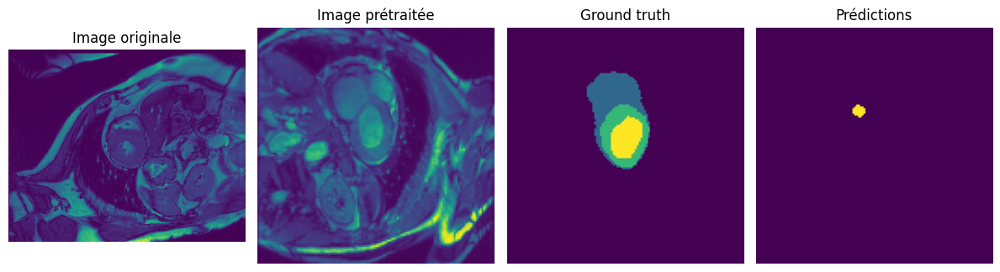

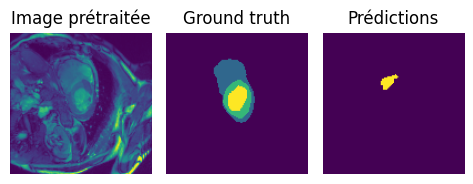

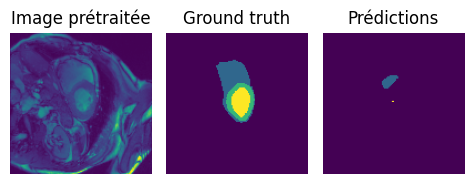

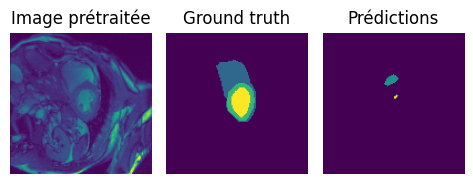

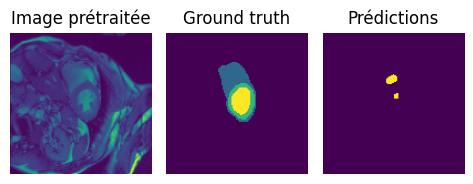

...

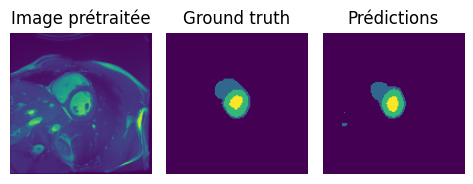

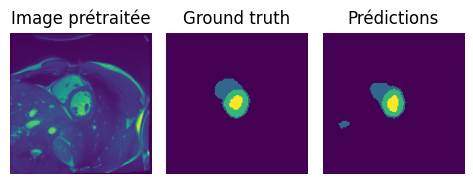

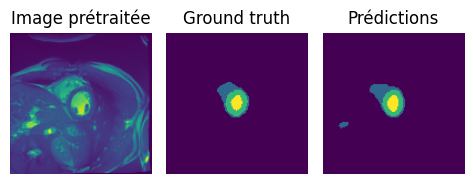

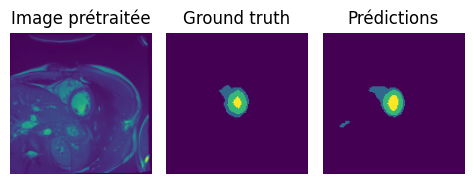

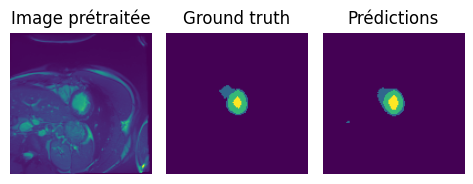

Buffered data was truncated after reaching the output size limit.

In [ ]:
""""""""""""""""""""""""""" Test de patient 24 """""""""""""""""""""""""""""""""
from scipy.ndimage import rotate
import matplotlib.pyplot as plt
import nibabel as nib
# Charger une image brute avec nibabel
image_path = '/content/drive/MyDrive/MyData/training/patient024/patient024_frame09.nii.gz'
img = nib.load(image_path)
reshaped_image = img.get_fdata()  # Convertir l'image NIfTI en tableau numpy

# Vérifier les dimensions des données
print("Image brute reshaped_image:", reshaped_image.shape)
print("Image prétraitée train_x1:", train_y1.shape)
print("Ground truth train_y1:", train_y1.shape)

# Configuration de l'affichage
plt.figure(figsize=(12, 8))

# Affichage de l'image originale
plt.subplot(1, 4, 1)
plt.imshow(reshaped_image[:, :, 2])  # Ajustez l'indice ici si nécessaire
plt.title('Image originale')
plt.axis('off')
for j in range(1,100):
  for i in range(1,10):
      # Affichage de l'image prétraitée
      plt.subplot(1, 4, 2)
      plt.imshow(train_x1[j,i , :, :, 0])  # Vérifiez les indices
      plt.title('Image prétraitée')
      plt.axis('off')

      # Affichage de la vérité terrain (ground truth)
      plt.subplot(1, 4, 3)
      plt.imshow(train_y1[j,i, :, :])  # Vérifiez l'indexation
      plt.title('Ground truth')
      plt.axis('off')

      # Affichage des prédictions
      plt.subplot(1, 4, 4)
      plt.imshow(pred[j,i, :, :])  # Vérifiez l'indexation
      plt.title('Prédictions')
      plt.axis('off')

      plt.tight_layout()
      plt.show()


In [ ]:
""""""""""""""""""""" Test de patient 2 slice 6 """""""""""""""""""""""""""
from scipy.ndimage import rotate
import matplotlib.pyplot as plt
import nibabel as nib

image_path = '/content/drive/MyDrive/MyData/training/patient002/patient002_frame01.nii.gz'
img = nib.load(image_path)
reshaped_image = img.get_fdata()  # Convertir l'image NIfTI en tableau numpy

# Vérifier les dimensions des données
print("Image brute reshaped_image:", reshaped_image.shape)
print("Image prétraitée train_x1:", X_train.shape)
print("Ground truth train_y1:", train_y1.shape)
print("Prédictions pred:", pred.shape)

# Configuration de l'affichage
plt.figure(figsize=(12, 8))

# Affichage de l'image brute originale
plt.subplot(1, 4, 1)
plt.imshow(reshaped_image[:, :, 6])  # Ajustez l'indice ici si nécessaire
plt.title('Image brute originale')
plt.axis('off')

# Affichage de l'image prétraitée
plt.subplot(1, 4, 2)
plt.imshow(X_train[2,6 , :, :, 0])  # Vérifiez les indices
plt.title('Image prétraitée')
plt.axis('off')

# Affichage de la vérité terrain (ground truth)
plt.subplot(1, 4, 3)
plt.imshow(train_y1[2 ,6, :, :])  # Vérifiez l'indexation
plt.title('Ground truth')
plt.axis('off')

# Affichage des prédictions
plt.subplot(1, 4, 4)
plt.imshow(pred[2,6, :, :])  # Vérifiez l'indexation
plt.title('Prédictions')
plt.axis('off')

plt.tight_layout()
plt.show()


Image brute reshaped_image: (232, 256, 10)


NameError: name 'X_train' is not defined

In [ ]:
"""""""""""""""""""""Test de patient 65 """""""""""""""""""""""""""
from scipy.ndimage import rotate
import matplotlib.pyplot as plt
import nibabel as nib
# Configuration de l'affichage
plt.figure(figsize=(12, 8))
# Charger une image brute avec nibabel
image_path = '/content/drive/MyDrive/MyData/training/patient095/patient095_frame01.nii.gz'
img = nib.load(image_path)
reshaped_image = img.get_fdata()  # Convertir l'image NIfTI en tableau numpy
plt.figure(figsize=(12, 8))
# Vérifier les dimensions des données
print("Image brute reshaped_image:", reshaped_image.shape)
print("Image prétraitée train_x1:", X_train.shape)
print("Ground truth train_y1:", train_y1.shape)
print("Prédictions pred:", pred.shape)
# Affichage de l'image brute originale
plt.subplot(1, 4, 1)
plt.imshow(reshaped_image[:, :, 5])  # Ajustez l'indice ici si nécessaire
plt.title('Image brute originale')
plt.axis('off')
for i in range(1,10):

    # Configuration de l'affichage
    plt.figure(figsize=(12, 8))



    # Affichage de l'image prétraitée
    plt.subplot(1, 4, 2)
    plt.imshow(X_train[95,i , :, :, 0])  # Vérifiez les indices
    plt.title('Image prétraitée ')
    plt.axis('off')

    # Affichage de la vérité terrain (ground truth)
    plt.subplot(1, 4, 3)
    plt.imshow(train_y1[95,i, :, :])  # Vérifiez l'indexation
    plt.title('Ground truth')
    plt.axis('off')

    # Affichage des prédictions
    plt.subplot(1, 4, 4)
    plt.imshow(pred[95,i, :, :])  # Vérifiez l'indexation
    plt.title('Prédictions')
    plt.axis('off')

    plt.tight_layout()
    plt.show()


In [ ]:
"""""""""""""""""""""Test de patient 65 """""""""""""""""""""""""""
from scipy.ndimage import rotate
import matplotlib.pyplot as plt
import nibabel as nib
# Configuration de l'affichage
plt.figure(figsize=(12, 8))
# Charger une image brute avec nibabel
image_path = '/content/drive/MyDrive/MyData/training/patient090/patient090_frame04.nii.gz'
img = nib.load(image_path)
reshaped_image = img.get_fdata()  # Convertir l'image NIfTI en tableau numpy
plt.figure(figsize=(12, 8))
# Vérifier les dimensions des données
print("Image brute reshaped_image:", reshaped_image.shape)
print("Image prétraitée train_x1:", X_train.shape)
print("Ground truth train_y1:", train_y1.shape)
print("Prédictions pred:", pred.shape)
# Affichage de l'image brute originale
plt.subplot(1, 4, 1)
plt.imshow(reshaped_image[:, :, 5])  # Ajustez l'indice ici si nécessaire
plt.title('Image brute originale')
plt.axis('off')
for i in range(1,10):

    # Configuration de l'affichage
    plt.figure(figsize=(12, 8))



    # Affichage de l'image prétraitée
    plt.subplot(1, 4, 2)
    plt.imshow(X_train[90,i , :, :, 0])  # Vérifiez les indices
    plt.title('Image prétraitée ')
    plt.axis('off')

    # Affichage de la vérité terrain (ground truth)
    plt.subplot(1, 4, 3)
    plt.imshow(train_y1[90,i, :, :])  # Vérifiez l'indexation
    plt.title('Ground truth')
    plt.axis('off')

    # Affichage des prédictions
    plt.subplot(1, 4, 4)
    plt.imshow(pred[90,i, :, :])  # Vérifiez l'indexation
    plt.title('Prédictions')
    plt.axis('off')

    plt.tight_layout()
    plt.show()


In [ ]:
"""""""""""""""""""""Test de patient 65 """""""""""""""""""""""""""
from scipy.ndimage import rotate
import matplotlib.pyplot as plt
import nibabel as nib
# Configuration de l'affichage
plt.figure(figsize=(12, 8))
# Charger une image brute avec nibabel
image_path = '/content/drive/MyDrive/MyData/training/patient083/patient083_frame01.nii.gz'
img = nib.load(image_path)
reshaped_image = img.get_fdata()  # Convertir l'image NIfTI en tableau numpy
plt.figure(figsize=(12, 8))
# Vérifier les dimensions des données
print("Image brute reshaped_image:", reshaped_image.shape)
print("Image prétraitée train_x1:", X_train.shape)
print("Ground truth train_y1:", train_y1.shape)
print("Prédictions pred:", pred.shape)
# Affichage de l'image brute originale
plt.subplot(1, 4, 1)
plt.imshow(reshaped_image[:, :, 5])  # Ajustez l'indice ici si nécessaire
plt.title('Image brute originale')
plt.axis('off')
for i in range(1,10):

    # Configuration de l'affichage
    plt.figure(figsize=(12, 8))



    # Affichage de l'image prétraitée
    plt.subplot(1, 4, 2)
    plt.imshow(X_train[83,i , :, :, 0])  # Vérifiez les indices
    plt.title('Image prétraitée ')
    plt.axis('off')

    # Affichage de la vérité terrain (ground truth)
    plt.subplot(1, 4, 3)
    plt.imshow(train_y1[83,i, :, :])  # Vérifiez l'indexation
    plt.title('Ground truth')
    plt.axis('off')

    # Affichage des prédictions
    plt.subplot(1, 4, 4)
    plt.imshow(pred[83,i, :, :])  # Vérifiez l'indexation
    plt.title('Prédictions')
    plt.axis('off')

    plt.tight_layout()
    plt.show()


In [ ]:
"""""""""""""""""""""Test de patient 65 """""""""""""""""""""""""""
from scipy.ndimage import rotate
import matplotlib.pyplot as plt
import nibabel as nib
# Configuration de l'affichage
plt.figure(figsize=(12, 8))
# Charger une image brute avec nibabel
image_path = '/content/drive/MyDrive/MyData/training/patient014/patient014_frame01.nii.gz'
img = nib.load(image_path)
reshaped_image = img.get_fdata()  # Convertir l'image NIfTI en tableau numpy
plt.figure(figsize=(12, 8))
# Vérifier les dimensions des données
print("Image brute reshaped_image:", reshaped_image.shape)
print("Image prétraitée train_x1:", X_train.shape)
print("Ground truth train_y1:", train_y1.shape)
print("Prédictions pred:", pred.shape)
# Affichage de l'image brute originale
plt.subplot(1, 4, 1)
plt.imshow(reshaped_image[:, :, 5])  # Ajustez l'indice ici si nécessaire
plt.title('Image brute originale')
plt.axis('off')
for i in range(1,10):

    # Configuration de l'affichage
    plt.figure(figsize=(12, 8))



    # Affichage de l'image prétraitée
    plt.subplot(1, 4, 2)
    plt.imshow(X_train[14,i , :, :, 0])  # Vérifiez les indices
    plt.title('Image prétraitée ')
    plt.axis('off')

    # Affichage de la vérité terrain (ground truth)
    plt.subplot(1, 4, 3)
    plt.imshow(train_y1[14,i, :, :])  # Vérifiez l'indexation
    plt.title('Ground truth')
    plt.axis('off')

    # Affichage des prédictions
    plt.subplot(1, 4, 4)
    plt.imshow(pred[14,i, :, :])  # Vérifiez l'indexation
    plt.title('Prédictions')
    plt.axis('off')

    plt.tight_layout()
    plt.show()


In [ ]:
"""""""""""""""""""""Test de patient 65 """""""""""""""""""""""""""
from scipy.ndimage import rotate
import matplotlib.pyplot as plt
import nibabel as nib
# Configuration de l'affichage
plt.figure(figsize=(12, 8))
# Charger une image brute avec nibabel
image_path = '/content/drive/MyDrive/MyData/training/patient099/patient099_frame01.nii.gz'
img = nib.load(image_path)
reshaped_image = img.get_fdata()  # Convertir l'image NIfTI en tableau numpy
plt.figure(figsize=(12, 8))
# Vérifier les dimensions des données
print("Image brute reshaped_image:", reshaped_image.shape)
print("Image prétraitée train_x1:", X_train.shape)
print("Ground truth train_y1:", train_y1.shape)
print("Prédictions pred:", pred.shape)
# Affichage de l'image brute originale
plt.subplot(1, 4, 1)
plt.imshow(reshaped_image[:, :, 5])  # Ajustez l'indice ici si nécessaire
plt.title('Image brute originale')
plt.axis('off')
for i in range(1,10):

    # Configuration de l'affichage
    plt.figure(figsize=(12, 8))



    # Affichage de l'image prétraitée
    plt.subplot(1, 4, 2)
    plt.imshow(X_train[99,i , :, :, 0])  # Vérifiez les indices
    plt.title('Image prétraitée ')
    plt.axis('off')

    # Affichage de la vérité terrain (ground truth)
    plt.subplot(1, 4, 3)
    plt.imshow(train_y1[99,i, :, :])  # Vérifiez l'indexation
    plt.title('Ground truth')
    plt.axis('off')

    # Affichage des prédictions
    plt.subplot(1, 4, 4)
    plt.imshow(pred[99,i, :, :])  # Vérifiez l'indexation
    plt.title('Prédictions')
    plt.axis('off')

    plt.tight_layout()
    plt.show()
